# Análise Exploratória — Online Shoppers Purchasing Intention

**Objetivo:** entender a base antes do pré-processamento e da classificação. Este notebook cobre:

1. Distribuição das classes e verificação de desbalanceamento
2. Valores ausentes
3. Duplicatas
4. Possíveis inconsistências e categorias raras
5. Outliers
6. Correlações
7. Atributos categóricos × classe

Os gráficos são salvos em `figuras/` e as tabelas em `tabelas/` (nesta mesma pasta), para uso no relatório.

## Configuração

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

# Raiz do projeto = primeira pasta (a partir da atual) que contém data/raw
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
PASTA = RAIZ / "01_analise_exploratoria"
ARQUIVO_DADOS = RAIZ / "data" / "raw" / "online_shoppers_intention.csv"
DIR_FIG = PASTA / "figuras"
DIR_TAB = PASTA / "tabelas"
DIR_FIG.mkdir(parents=True, exist_ok=True)
DIR_TAB.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
CLASSE = "Revenue"
NUMERICOS = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
CATEGORICOS = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend",
]
CONTAGENS = ["Administrative", "Informational", "ProductRelated"]
ORDEM_MESES = ["Jan", "Feb", "Mar", "Apr", "May", "June",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
# Atributos muito assimétricos: exibidos em escala log(1 + x)
ASSIMETRICOS = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration", "PageValues",
]
ROTULO_CLASSE = {False: "Não comprou (False)", True: "Comprou (True)"}

In [3]:
# Estilo dos gráficos
COR = {
    False: "#2a78d6",   # azul    -> classe majoritária
    True: "#eb6834",    # laranja -> classe minoritária
    "unica": "#2a78d6",
    "texto": "#0b0b0b",
    "texto2": "#52514e",
    "mudo": "#898781",
    "grade": "#e1e0d9",
    "eixo": "#c3c2b7",
    "fundo": "#fcfcfb",
}
MAPA_DIVERGENTE = LinearSegmentedColormap.from_list(
    "azul_cinza_vermelho", ["#1c5cab", "#f0efec", "#c23636"]
)

plt.rcParams.update({
    "figure.facecolor": COR["fundo"],
    "axes.facecolor": COR["fundo"],
    "savefig.facecolor": COR["fundo"],
    "axes.edgecolor": COR["eixo"],
    "axes.labelcolor": COR["texto2"],
    "axes.titlecolor": COR["texto"],
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": COR["grade"],
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "xtick.color": COR["texto2"],
    "ytick.color": COR["texto2"],
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "font.size": 9,
    "figure.dpi": 100,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})


def salvar_tabela(tabela, nome, index=True):
    tabela.to_csv(DIR_TAB / f"{nome}.csv", index=index, float_format="%.4f")


def salvar_figura(fig, nome):
    """Salva o PNG em figuras/ e exibe o gráfico no notebook."""
    fig.savefig(DIR_FIG / f"{nome}.png")
    plt.show()


def legenda_classes(fig, **kwargs):
    alcas = [Rectangle((0, 0), 1, 1, color=COR[c]) for c in (False, True)]
    fig.legend(alcas, [ROTULO_CLASSE[False], ROTULO_CLASSE[True]],
               ncol=2, loc="upper center", **kwargs)

## 0. Visão geral da base

In [4]:
df = pd.read_csv(ARQUIVO_DADOS)
n_total = len(df)

print(f"Instâncias: {n_total} | Atributos: {df.shape[1]} ({df.shape[1] - 1} preditores + 1 classe)")
print(f"Numéricos ({len(NUMERICOS)}): {', '.join(NUMERICOS)}")
print(f"Categóricos ({len(CATEGORICOS)}): {', '.join(CATEGORICOS)}")
print(f"Classe: {CLASSE}")
df.head()

Instâncias: 12330 | Atributos: 18 (17 preditores + 1 classe)
Numéricos (10): Administrative, Administrative_Duration, Informational, Informational_Duration, ProductRelated, ProductRelated_Duration, BounceRates, ExitRates, PageValues, SpecialDay
Categóricos (7): Month, OperatingSystems, Browser, Region, TrafficType, VisitorType, Weekend
Classe: Revenue


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0000,0,0.0000,2,64.0000,0.0000,0.1000,0.0000,0.0000,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0000,0,0.0000,2,2.6667,0.0500,0.1400,0.0000,0.0000,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0000,0,0.0000,10,627.5000,0.0200,0.0500,0.0000,0.0000,Feb,3,3,1,4,Returning_Visitor,True,False


In [5]:
tipos = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "tipo_semantico": ["numérico" if c in NUMERICOS else
                       "classe" if c == CLASSE else "categórico"
                       for c in df.columns],
    "valores_distintos": df.nunique(),
})
salvar_tabela(tipos, "00_tipos_atributos")
tipos

,tipo_pandas,tipo_semantico,valores_distintos
Administrative,int64,numérico,27
Administrative_Duration,float64,numérico,3335
Informational,int64,numérico,17
Informational_Duration,float64,numérico,1258
ProductRelated,int64,numérico,311
ProductRelated_Duration,float64,numérico,9551
BounceRates,float64,numérico,1872
ExitRates,float64,numérico,4777
PageValues,float64,numérico,2704
SpecialDay,float64,numérico,6


## 1. Distribuição das classes

Verifica a proporção de sessões com e sem compra (`Revenue`) e se existe desbalanceamento.

In [6]:
dist = (df[CLASSE].value_counts()
        .rename("quantidade").to_frame()
        .assign(percentual=lambda t: 100 * t["quantidade"] / n_total))
dist.index = dist.index.map(ROTULO_CLASSE)
salvar_tabela(dist, "01_distribuicao_classes")

razao = dist["quantidade"].max() / dist["quantidade"].min()
print(f"Razão de desbalanceamento (maioria/minoria): {razao:.2f} : 1")
print(f"Acurácia de um classificador que sempre prevê 'False': {dist['percentual'].max():.2f}%")
dist

Razão de desbalanceamento (maioria/minoria): 5.46 : 1
Acurácia de um classificador que sempre prevê 'False': 84.53%


,quantidade,percentual
Revenue,,
Não comprou (False),10422,84.5255
Comprou (True),1908,15.4745


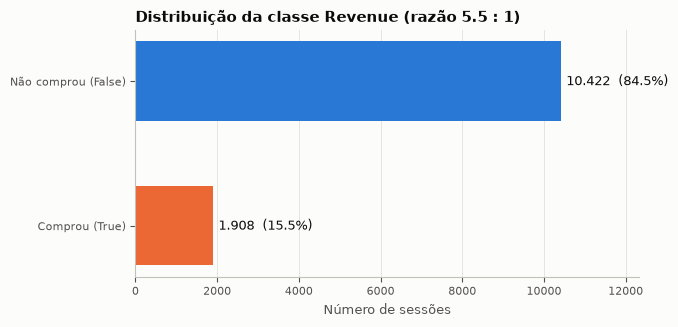

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
classes = [False, True]
qtds = [int((df[CLASSE] == c).sum()) for c in classes]
barras = ax.barh([ROTULO_CLASSE[c] for c in classes], qtds,
                 color=[COR[c] for c in classes], height=0.55)
for barra, q in zip(barras, qtds):
    ax.text(barra.get_width() + n_total * 0.01, barra.get_y() + barra.get_height() / 2,
            f"{q:,}".replace(",", ".") + f"  ({100 * q / n_total:.1f}%)",
            va="center", color=COR["texto"], fontsize=9)
ax.set_xlim(0, n_total)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Número de sessões")
ax.set_title(f"Distribuição da classe Revenue (razão {razao:.1f} : 1)", loc="left")
salvar_figura(fig, "01_distribuicao_classes")

## 2. Valores ausentes

Além de `NaN`, verifica marcadores de ausência disfarçados (`?`, `NA`, texto vazio etc.)
e valores negativos em atributos que não deveriam tê-los (ex.: `-1` usado como "sem informação").

In [8]:
ausentes = pd.DataFrame({
    "ausentes": df.isna().sum(),
    "percentual": 100 * df.isna().mean(),
})
salvar_tabela(ausentes, "02_valores_ausentes")

marcadores = {"", "?", "NA", "N/A", "null", "None", "nan", "-"}
disfarcados = sum(int(df[c].astype(str).str.strip().isin(marcadores).sum()) for c in df.columns)
negativos = int((df[NUMERICOS] < 0).sum().sum())

print(f"Total de células ausentes (NaN): {int(ausentes['ausentes'].sum())}")
print(f"Marcadores de ausência disfarçados: {disfarcados}")
print(f"Valores negativos em atributos numéricos: {negativos}")
ausentes.T

Total de células ausentes (NaN): 0
Marcadores de ausência disfarçados: 0
Valores negativos em atributos numéricos: 0


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
ausentes,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
percentual,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


## 3. Duplicatas

Conta linhas idênticas e verifica se existem **conflitos**: instâncias com os mesmos
atributos preditores mas classes diferentes.

In [9]:
mask_dup = df.duplicated(keep="first")          # cópias excedentes
mask_dup_todas = df.duplicated(keep=False)      # cópias + originais
n_dup = int(mask_dup.sum())

print(f"Linhas duplicadas (cópias excedentes): {n_dup} ({100 * n_dup / n_total:.2f}%)")
print(f"Linhas envolvidas em duplicação (incluindo a original): {int(mask_dup_todas.sum())}")
print(f"Grupos distintos de linhas repetidas: {df[mask_dup_todas].drop_duplicates().shape[0]}")
print("Classe das cópias excedentes:",
      ", ".join(f"{ROTULO_CLASSE[k]}={v}" for k, v in df.loc[mask_dup, CLASSE].value_counts().items()))

preditores = [c for c in df.columns if c != CLASSE]
rotulos_por_grupo = df.groupby(preditores, dropna=False)[CLASSE].nunique()
print(f"Grupos com preditores idênticos e classes DIFERENTES (conflito): {int((rotulos_por_grupo > 1).sum())}")

print(f"Cópias com ProductRelated_Duration = 0: "
      f"{100 * (df.loc[mask_dup, 'ProductRelated_Duration'] == 0).mean():.1f}%")
saida_imediata = (df.loc[mask_dup, "BounceRates"] == 0.2) & (df.loc[mask_dup, "ExitRates"] == 0.2)
print(f"Cópias com BounceRates = ExitRates = 0.2 (saída imediata): {100 * saida_imediata.mean():.1f}%")

Linhas duplicadas (cópias excedentes): 125 (1.01%)
Linhas envolvidas em duplicação (incluindo a original): 201
Grupos distintos de linhas repetidas: 76
Classe das cópias excedentes: Não comprou (False)=125
Grupos com preditores idênticos e classes DIFERENTES (conflito): 0
Cópias com ProductRelated_Duration = 0: 100.0%
Cópias com BounceRates = ExitRates = 0.2 (saída imediata): 100.0%


In [10]:
# Grupos de linhas repetidas, do mais frequente para o menos frequente
grupos_dup = (df[mask_dup_todas].value_counts().rename("ocorrencias")
              .reset_index().sort_values("ocorrencias", ascending=False))
salvar_tabela(grupos_dup, "03_grupos_duplicados", index=False)

dup_perfil = df.loc[mask_dup, NUMERICOS].agg(["mean", "median"]).T
dup_perfil.columns = ["media_duplicatas", "mediana_duplicatas"]
dup_perfil["media_base"] = df[NUMERICOS].mean()
salvar_tabela(dup_perfil, "03_perfil_duplicatas")

grupos_dup.head(100)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,ocorrencias
0,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Mar,2,2,1,1,Returning_Visitor,False,False,14
1,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Mar,3,2,3,1,Returning_Visitor,False,False,7
2,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,May,2,2,1,3,Returning_Visitor,False,False,7
3,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,May,1,1,1,3,Returning_Visitor,False,False,6
4,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Dec,8,13,9,20,Other,False,False,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,0,0.0000,0,0.0000,2,0.0000,0.2000,0.2000,0.0000,0.0000,Nov,1,1,1,1,Returning_Visitor,False,False,2
72,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Dec,3,2,6,1,Returning_Visitor,False,False,2
73,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Nov,2,4,3,3,Returning_Visitor,False,False,2
74,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Dec,1,1,1,3,Returning_Visitor,False,False,2


## 4. Possíveis inconsistências

In [11]:
meses = set(df["Month"])
print("Meses presentes:", ", ".join(m for m in ORDEM_MESES if m in meses))
print("Meses AUSENTES:", ", ".join(m for m in ORDEM_MESES if m not in meses))
print("Grafia fora do padrão de 3 letras:", ", ".join(sorted(m for m in meses if len(m) != 3)))
print("Valores distintos de SpecialDay:", sorted(df["SpecialDay"].unique().tolist()))
print("VisitorType:", ", ".join(f"{k}={v}" for k, v in df["VisitorType"].value_counts().items()))

Meses presentes: Feb, Mar, May, June, Jul, Aug, Sep, Oct, Nov, Dec
Meses AUSENTES: Jan, Apr
Grafia fora do padrão de 3 letras: June
Valores distintos de SpecialDay: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
VisitorType: Returning_Visitor=10551, New_Visitor=1694, Other=85


Categorias com menos de 1% das sessões (podem gerar instabilidade em codificação one-hot e em validação cruzada):

In [12]:
raras = []
for c in ["OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]:
    freq = df[c].value_counts()
    for cat, q in freq[freq / n_total < 0.01].items():
        raras.append({"atributo": c, "categoria": cat, "quantidade": int(q),
                      "percentual": 100 * q / n_total})
raras = pd.DataFrame(raras)
salvar_tabela(raras, "04_categorias_raras", index=False)

display(raras.groupby("atributo").size().rename("n_categorias_raras").to_frame())
raras

,n_categorias_raras
atributo,
Browser,6
OperatingSystems,4
TrafficType,9
VisitorType,1


,atributo,categoria,quantidade,percentual
0,OperatingSystems,8,79,0.6407
1,OperatingSystems,6,19,0.1541
2,OperatingSystems,7,7,0.0568
3,OperatingSystems,5,6,0.0487
4,Browser,3,105,0.8516
5,Browser,13,61,0.4947
6,Browser,7,49,0.3974
7,Browser,12,10,0.0811
8,Browser,11,6,0.0487
9,Browser,9,1,0.0081


## 5. Outliers

Dois critérios:
- **Tukey (IQR):** valores fora de `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]`;
- **z-score:** `|z| > 3`.

Atenção: quando `IQR = 0` (atributos com mais de 75% de zeros), todo valor diferente de zero é marcado como outlier.

In [13]:
linhas_out = []
for c in NUMERICOS:
    s = df[c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    m_iqr = (s < lim_inf) | (s > lim_sup)
    m_z = ((s - s.mean()) / s.std()).abs() > 3
    linhas_out.append({
        "atributo": c, "Q1": q1, "Q3": q3, "IQR": iqr,
        "limite_inferior": lim_inf, "limite_superior": lim_sup,
        "outliers_iqr": int(m_iqr.sum()),
        "pct_outliers_iqr": 100 * m_iqr.mean(),
        "pct_comprou_entre_outliers_iqr": 100 * df.loc[m_iqr, CLASSE].mean() if m_iqr.any() else np.nan,
        "outliers_z3": int(m_z.sum()),
        "pct_outliers_z3": 100 * m_z.mean(),
        "iqr_igual_zero": iqr == 0,
    })
outliers = pd.DataFrame(linhas_out).set_index("atributo")
salvar_tabela(outliers, "06_outliers")

print(f"Taxa geral de compra: {100 * df[CLASSE].mean():.2f}% -> compare com pct_comprou_entre_outliers_iqr")
print(f"Sessões com ProductRelated_Duration > 10 h: {int((df['ProductRelated_Duration'] > 36000).sum())} "
      f"(máximo = {df['ProductRelated_Duration'].max() / 3600:.1f} h)")
outliers

Taxa geral de compra: 15.47% -> compare com pct_comprou_entre_outliers_iqr
Sessões com ProductRelated_Duration > 10 h: 2 (máximo = 17.8 h)


,Q1,Q3,IQR,limite_inferior,limite_superior,outliers_iqr,pct_outliers_iqr,pct_comprou_entre_outliers_iqr,outliers_z3,pct_outliers_z3,iqr_igual_zero
atributo,,,,,,,,,,,
Administrative,0.0000,4.0000,4.0000,-6.0000,10.0000,404,3.2766,27.2277,213,1.7275,False
Administrative_Duration,0.0000,93.2562,93.2562,-139.8844,233.1406,1172,9.5053,24.7440,232,1.8816,False
Informational,0.0000,0.0000,0.0000,0.0000,0.0000,2631,21.3382,23.2991,260,2.1087,True
Informational_Duration,0.0000,0.0000,0.0000,0.0000,0.0000,2405,19.5053,23.4927,230,1.8654,True
ProductRelated,7.0000,38.0000,31.0000,-39.5000,84.5000,987,8.0049,28.8754,236,1.9140,False
ProductRelated_Duration,184.1375,1464.1572,1280.0197,-1735.8921,3384.1868,961,7.7940,30.0728,219,1.7762,False
BounceRates,0.0000,0.0168,0.0168,-0.0252,0.0420,1551,12.5791,1.6119,708,5.7421,False
ExitRates,0.0143,0.0500,0.0357,-0.0393,0.1036,1099,8.9132,0.5460,713,5.7826,False
PageValues,0.0000,0.0000,0.0000,0.0000,0.0000,2730,22.1411,56.3370,259,2.1006,True


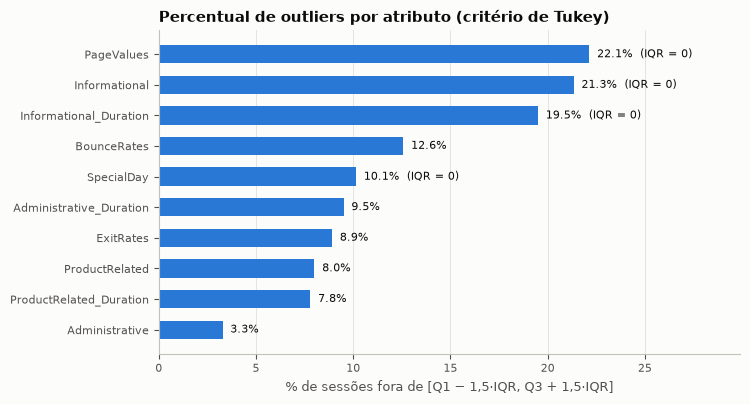

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ordem = outliers.sort_values("pct_outliers_iqr")
barras = ax.barh(ordem.index, ordem["pct_outliers_iqr"], color=COR["unica"], height=0.6)
for barra, (nome, linha) in zip(barras, ordem.iterrows()):
    sufixo = "  (IQR = 0)" if linha["iqr_igual_zero"] else ""
    ax.text(barra.get_width() + 0.4, barra.get_y() + barra.get_height() / 2,
            f"{linha['pct_outliers_iqr']:.1f}%{sufixo}", va="center",
            color=COR["texto"], fontsize=8)
ax.set_xlim(0, ordem["pct_outliers_iqr"].max() * 1.35)
ax.set_xlabel("% de sessões fora de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]")
ax.grid(axis="y", visible=False)
ax.set_title("Percentual de outliers por atributo (critério de Tukey)", loc="left")
salvar_figura(fig, "04_percentual_outliers")

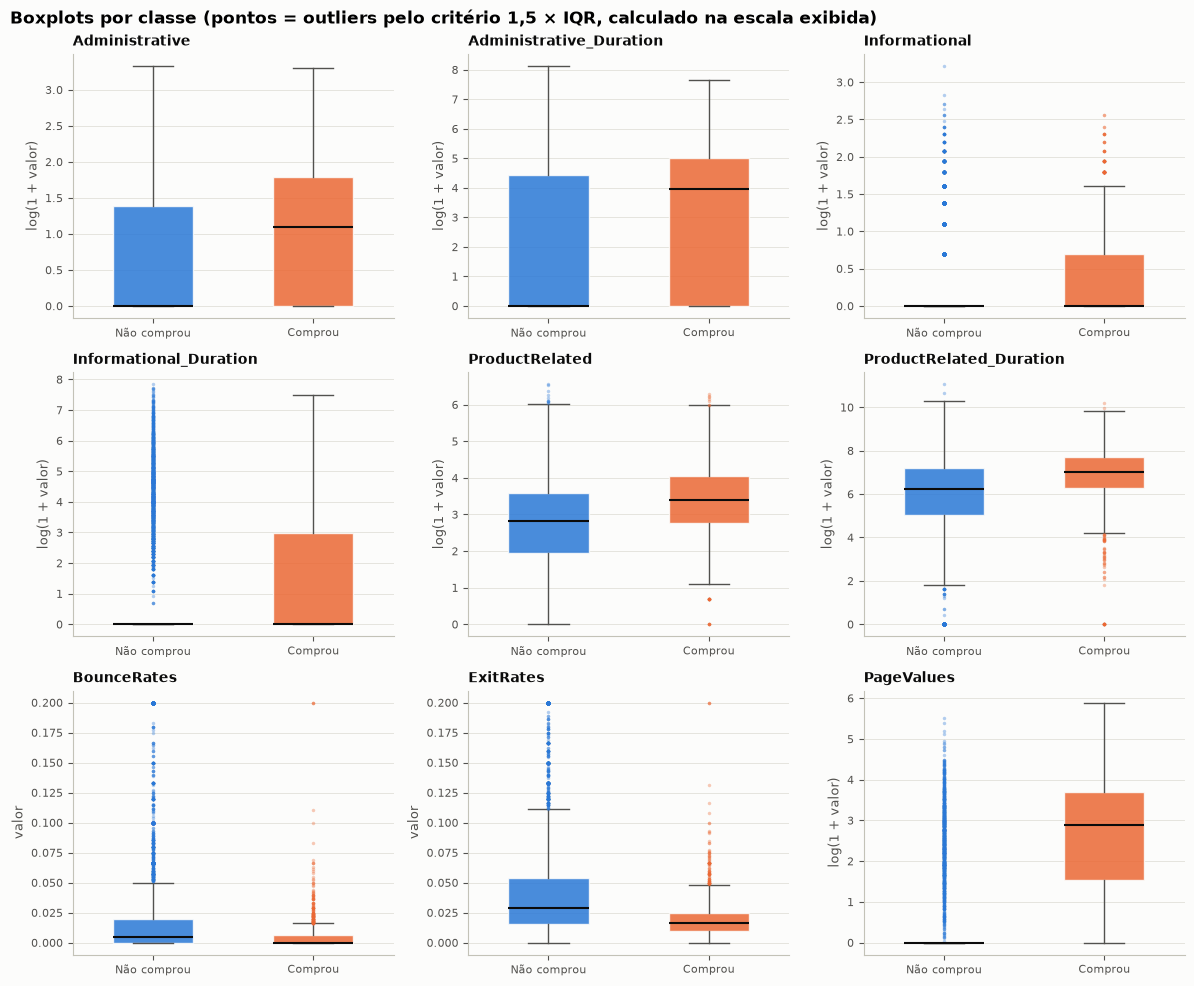

In [15]:
NUM_BOX = [c for c in NUMERICOS if c != "SpecialDay"]
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for ax, c in zip(axes.ravel(), NUM_BOX):
    grupos = [np.log1p(df.loc[df[CLASSE] == cl, c]) if c in ASSIMETRICOS
              else df.loc[df[CLASSE] == cl, c] for cl in (False, True)]
    bp = ax.boxplot(grupos, widths=0.5, patch_artist=True,
                    medianprops={"color": COR["texto"], "linewidth": 1.5},
                    flierprops={"marker": "o", "markersize": 2.5, "alpha": 0.35, "markeredgewidth": 0},
                    whiskerprops={"color": COR["texto2"]},
                    capprops={"color": COR["texto2"]})
    for caixa, fl, cl in zip(bp["boxes"], bp["fliers"], (False, True)):
        caixa.set_facecolor(COR[cl])
        caixa.set_alpha(0.85)
        caixa.set_edgecolor(COR["fundo"])
        fl.set_markerfacecolor(COR[cl])
    ax.set_xticks([1, 2], ["Não comprou", "Comprou"])
    ax.set_title(c, fontsize=10, loc="left")
    ax.set_ylabel("log(1 + valor)" if c in ASSIMETRICOS else "valor")
    ax.grid(axis="x", visible=False)
fig.suptitle("Boxplots por classe (pontos = outliers pelo critério 1,5 × IQR, calculado na escala exibida)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
salvar_figura(fig, "03_boxplots_por_classe")

`PageValues` merece atenção especial: compare a presença de valores > 0 em cada classe.

In [16]:
pv = df.groupby(CLASSE)["PageValues"].apply(lambda s: 100 * (s > 0).mean())
print(f"PageValues > 0 entre quem NÃO comprou: {pv[False]:.1f}% | entre quem comprou: {pv[True]:.1f}%")
print(f"Taxa de compra quando PageValues > 0: {100 * df.loc[df['PageValues'] > 0, CLASSE].mean():.1f}% | "
      f"quando = 0: {100 * df.loc[df['PageValues'] == 0, CLASSE].mean():.1f}%")

PageValues > 0 entre quem NÃO comprou: 11.4% | entre quem comprou: 80.6%
Taxa de compra quando PageValues > 0: 56.3% | quando = 0: 3.9%


## 6. Correlações

Usa-se Spearman (baseada em postos) porque os atributos são muito assimétricos e cheios de zeros;
a classe entra como 0/1.

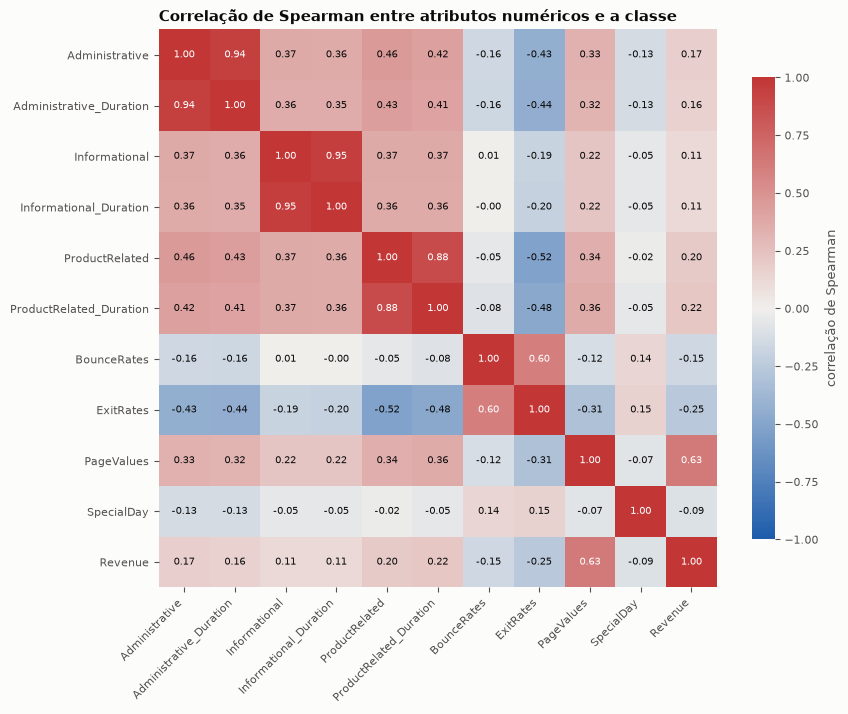

In [17]:
corr = df[NUMERICOS + [CLASSE]].astype(float).corr(method="spearman")
salvar_tabela(corr, "07_correlacao_spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap=MAPA_DIVERGENTE, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="#ffffff" if abs(v) > 0.6 else COR["texto"])
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.outline.set_visible(False)
cb.set_label("correlação de Spearman")
ax.set_title("Correlação de Spearman entre atributos numéricos e a classe", loc="left")
salvar_figura(fig, "05_correlacao_spearman")

In [18]:
print("Correlação de cada atributo com Revenue:")
display(corr[CLASSE].drop(CLASSE).sort_values(ascending=False).to_frame("rho_revenue"))

mascara_sup = np.triu(np.ones((len(NUMERICOS),) * 2, dtype=bool), k=1)
pares = (corr.drop(index=CLASSE, columns=CLASSE).where(mascara_sup)
         .stack().sort_values(key=abs, ascending=False))
print("Pares de preditores mais correlacionados (|rho| > 0.7):")
pares[pares.abs() > 0.7].to_frame("rho")

Correlação de cada atributo com Revenue:


,rho_revenue
PageValues,0.6264
ProductRelated_Duration,0.2168
ProductRelated,0.1985
Administrative,0.1679
Administrative_Duration,0.1640
Informational,0.1139
Informational_Duration,0.1121
SpecialDay,-0.0869
BounceRates,-0.1490
ExitRates,-0.2545


Pares de preditores mais correlacionados (|rho| > 0.7):


,,rho
Informational,Informational_Duration,0.9510
Administrative,Administrative_Duration,0.9407
ProductRelated,ProductRelated_Duration,0.8827


## 7. Atributos categóricos × classe


In [19]:
taxa_geral = 100 * df[CLASSE].mean()
CAT_PLOT = CATEGORICOS + ["SpecialDay"]
tabelas_cat = []
for c in CAT_PLOT:
    t = (df.groupby(c)[CLASSE].agg(quantidade="size", compras="sum")
         .assign(pct_sessoes=lambda x: 100 * x["quantidade"] / n_total,
                 taxa_compra=lambda x: 100 * x["compras"] / x["quantidade"]))
    if c == "Month":
        t = t.reindex([m for m in ORDEM_MESES if m in t.index])
    t.insert(0, "atributo", c)
    tabelas_cat.append(t.reset_index().rename(columns={c: "categoria"}))
tab_cat = pd.concat(tabelas_cat, ignore_index=True)
salvar_tabela(tab_cat, "08_taxa_compra_por_categoria", index=False)

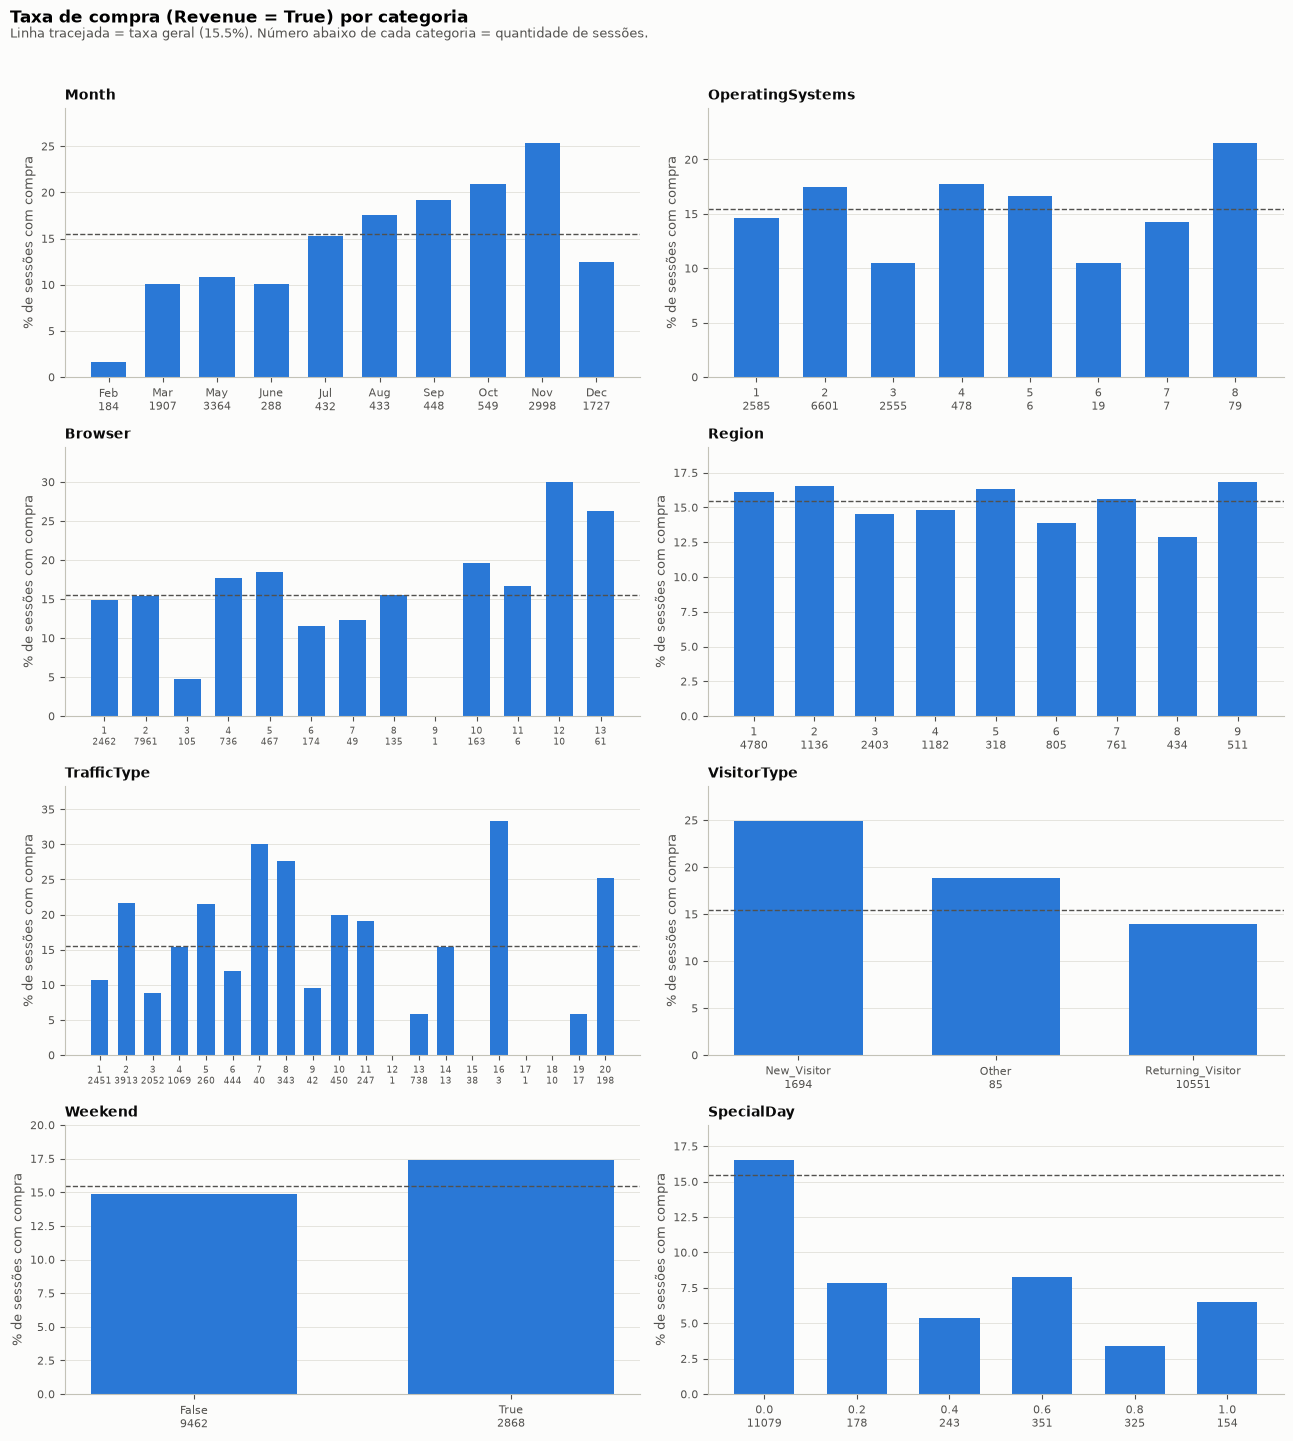

In [20]:
fig, axes = plt.subplots(4, 2, figsize=(13, 14))
for ax, c in zip(axes.ravel(), CAT_PLOT):
    sub = tab_cat[tab_cat["atributo"] == c]
    rotulos = sub["categoria"].astype(str).tolist()
    x = np.arange(len(sub))
    ax.bar(x, sub["taxa_compra"], color=COR["unica"], width=0.65)
    ax.axhline(taxa_geral, color=COR["texto2"], linestyle="--", linewidth=1)
    ax.set_xticks(x, [f"{r}\n{q}" for r, q in zip(rotulos, sub["quantidade"])],
                  fontsize=8 if len(sub) <= 10 else 6.5)
    ax.set_ylim(0, max(sub["taxa_compra"].max(), taxa_geral) * 1.15)
    ax.set_ylabel("% de sessões com compra")
    ax.set_title(c, fontsize=10, loc="left")
    ax.grid(axis="x", visible=False)
fig.suptitle("Taxa de compra (Revenue = True) por categoria", x=0.01, ha="left",
             y=1.025, fontweight="bold", fontsize=12)
fig.text(0.01, 1.005, f"Linha tracejada = taxa geral ({taxa_geral:.1f}%). "
         "Número abaixo de cada categoria = quantidade de sessões.",
         ha="left", fontsize=9, color=COR["texto2"])
fig.tight_layout()
salvar_figura(fig, "06_taxa_compra_por_categoria")

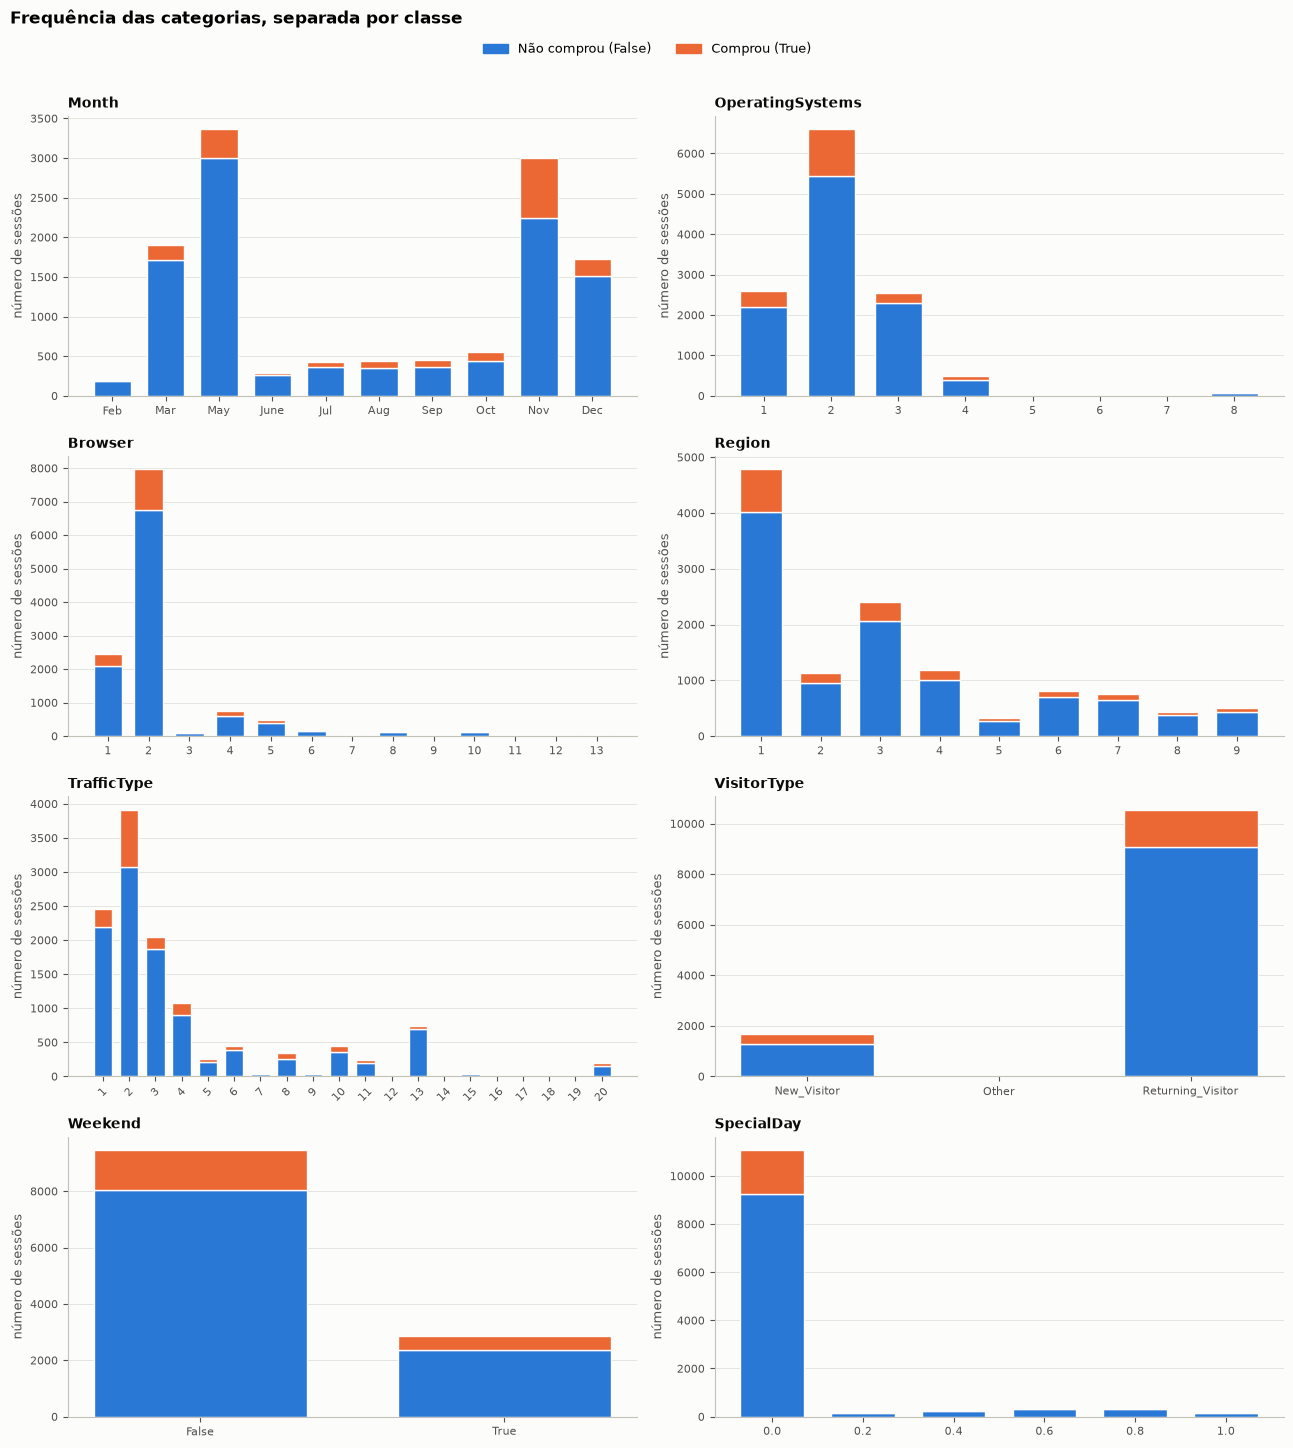

In [21]:
fig, axes = plt.subplots(4, 2, figsize=(13, 14))
for ax, c in zip(axes.ravel(), CAT_PLOT):
    sub = tab_cat[tab_cat["atributo"] == c]
    x = np.arange(len(sub))
    nao = sub["quantidade"] - sub["compras"]
    ax.bar(x, nao, color=COR[False], width=0.7, edgecolor=COR["fundo"], linewidth=1)
    ax.bar(x, sub["compras"], bottom=nao, color=COR[True], width=0.7,
           edgecolor=COR["fundo"], linewidth=1)
    ax.set_xticks(x, sub["categoria"].astype(str), rotation=0 if len(sub) <= 13 else 45)
    ax.set_ylabel("número de sessões")
    ax.set_title(c, fontsize=10, loc="left")
    ax.grid(axis="x", visible=False)
legenda_classes(fig, bbox_to_anchor=(0.5, 1.015))
fig.suptitle("Frequência das categorias, separada por classe", x=0.01, ha="left",
             y=1.03, fontweight="bold", fontsize=12)
fig.tight_layout()
salvar_figura(fig, "07_frequencia_categorias_por_classe")

## Principais observações

- **Desbalanceamento:** 84,5% das sessões não terminam em compra e 15,5% terminam (razão ≈ 5,5 : 1).
  Um classificador trivial que sempre responde "não comprou" já acerta 84,5%, então a acurácia sozinha não serve
  como medida de avaliação.
- **Valores ausentes:** nenhum, nem disfarçado.
- **Duplicatas:** 125 linhas (1,0%), todas da classe "não comprou" e todas com o mesmo padrão de sessão de
  saída imediata (`BounceRates = ExitRates = 0.2`, sem tempo em páginas de produto). Não há conflito de rótulo.
- **Inconsistências:** categoria `Other` em `VisitorType` (85 sessões), não citada na documentação; meses `Jan` e
  `Apr` ausentes e `June` fora do padrão de três letras; `SpecialDay` assume apenas 6 valores discretos (0 a 1, de 0,2
  em 0,2); várias categorias raras (< 1% das sessões) em `Browser`, `OperatingSystems` e `TrafficType`.
- **Outliers:** pelo critério de Tukey, vão de 3,3% (`Administrative`) a 22,1% (`PageValues`) das sessões. Em
  `Informational`, `Informational_Duration`, `PageValues` e `SpecialDay` o IQR é 0, então todo valor diferente de zero
  é contado como outlier. As sessões marcadas como outlier nos atributos de navegação compram **mais** que a média
  (23% a 30%, contra 15,5%), ou seja, carregam informação e não parecem erros.
- **Atributos mais associados à classe:** `PageValues` (ρ = 0,63): quando é maior que zero, 56,3% das sessões compram;
  quando é zero, só 3,9%. Em seguida vêm `ExitRates` (ρ = −0,25) e os atributos de produto. Contagens e durações de um
  mesmo tipo de página são fortemente correlacionadas (ρ de 0,88 a 0,95).
- **Categóricos:** taxa de compra varia bastante com o mês (1,6% em fevereiro, 25,4% em novembro) e com o
  tipo de visitante (novos 24,9%, recorrentes 13,9%).